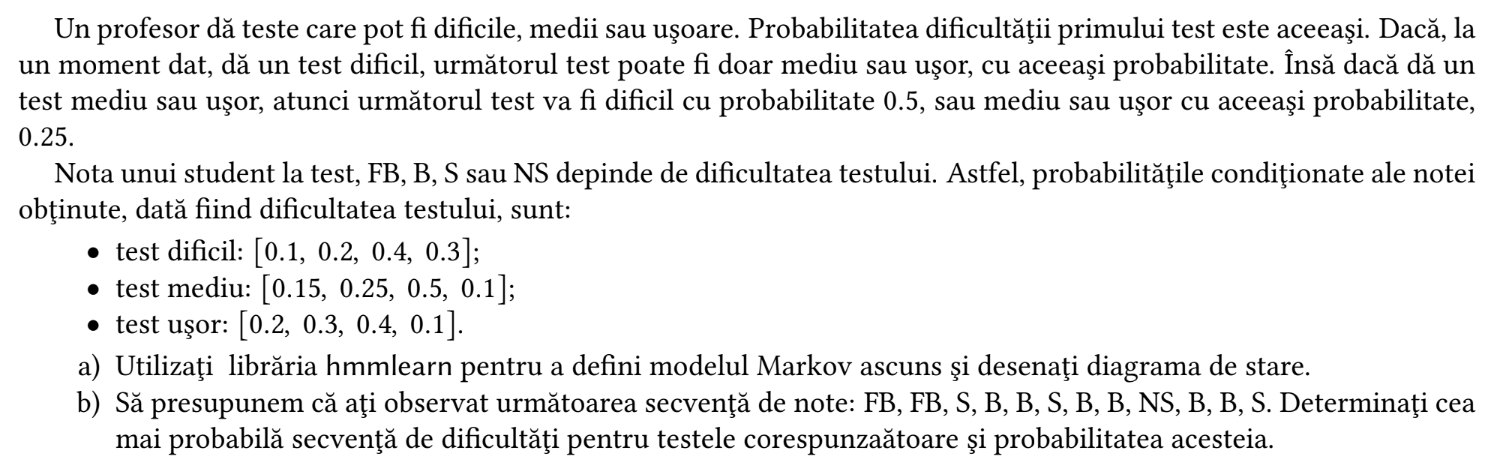

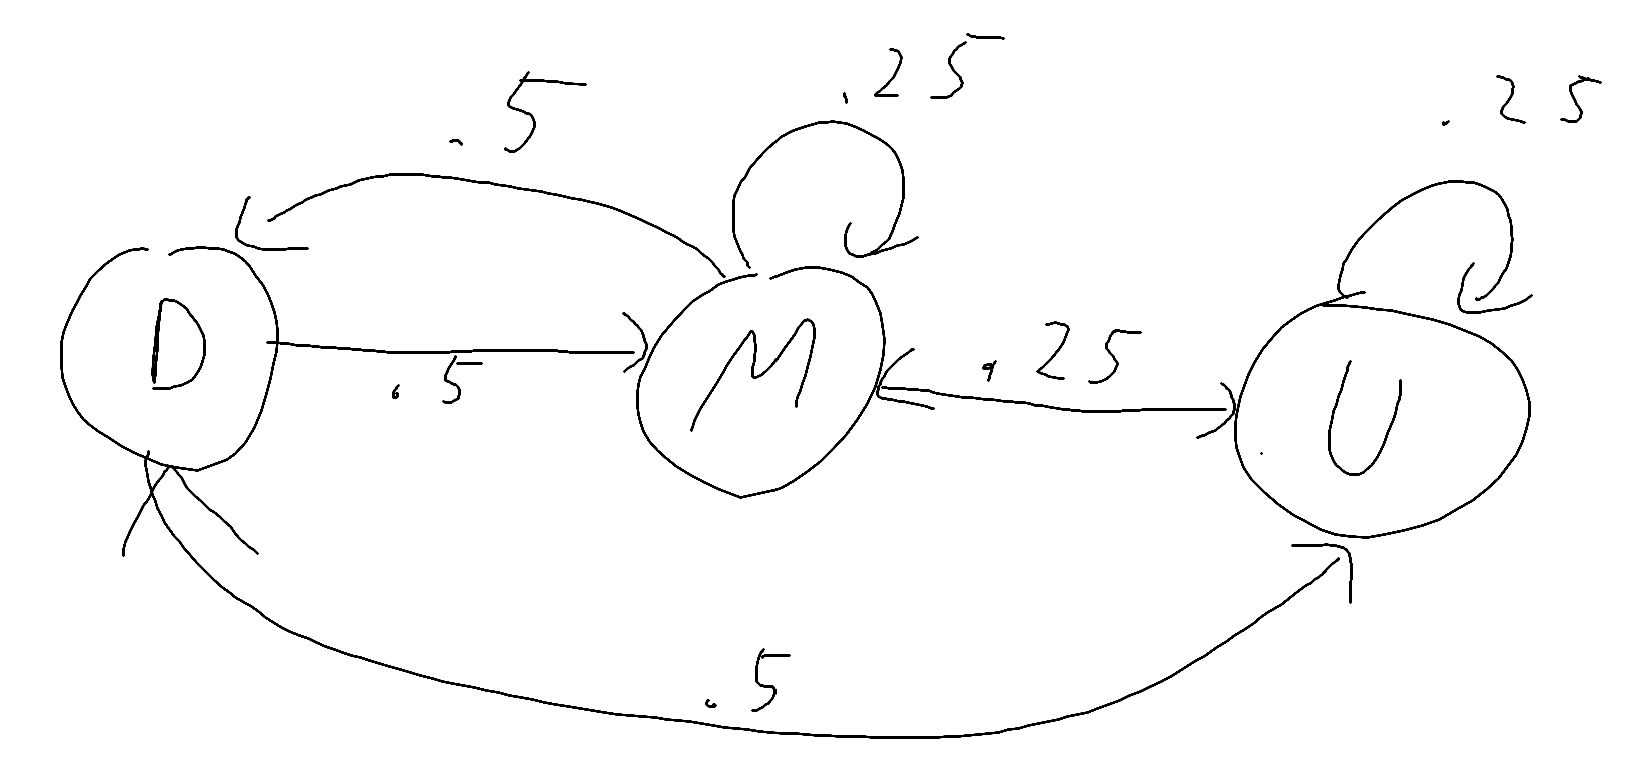

In [3]:
import numpy as np
from hmmlearn import hmm

startp = np.array([1/3, 1/3, 1/3])

tranzp = np.array([
    [0.0,  0.5,  0.5 ],  #din dificil
    [0.5,  0.25, 0.25],  #mediu
    [0.5,  0.25, 0.25]   #usor
])

notep = np.array([
    [0.1,  0.2,  0.4, 0.3],  #dificil
    [0.15, 0.25, 0.5, 0.1],  #mediu
    [0.2,  0.3,  0.4, 0.1]   #usor
])

model = hmm.CategoricalHMM(n_components=3)
model.startprob_ = startp
model.transmat_ = tranzp
model.emissionprob_ = notep

In [4]:
#viterbi: pentru a afla starea t+1 avem nevoie doar de t
#viterbi e un dp in care retinem pt un moment de timp t, pentur fiecare stare cea mai mare prob de a ajunge in ea

observatii = np.array([[0, 0, 2, 1, 1, 2, 1, 1, 3, 1, 1, 2]]).T

logprob, seq = model.decode(observatii, algorithm="viterbi")

states_name = ["Dificil", "Mediu", "Ușor"]
predicted_states = [states_name[i] for i in seq]

print(predicted_states)
print(np.exp(logprob))

['Ușor', 'Ușor', 'Dificil', 'Ușor', 'Dificil', 'Mediu', 'Dificil', 'Ușor', 'Dificil', 'Ușor', 'Dificil', 'Mediu']
2.109375000000024e-11
